# Détection de caractéristiques

In [1]:
import numpy as np
import skimage.io as io
import matplotlib.pyplot as plt
from skimage.transform import resize
from skimage.feature import match_template
from skimage.feature import match_descriptors, plot_matched_features, SIFT
import time

In [2]:
# Génération des panneaux en niveau de gris et à la bonne dimension
if False:

    from skimage.color import rgba2rgb, rgb2gray
    from skimage.transform import resize
    from skimage import img_as_ubyte

    # Dimension de sortie des panneaux
    N = 48

    panels = [50, 70, 90, 110, 130]
    for p in panels:

        # Chargement de l'image RGBA
        sign = io.imread(f"P256/P{p}.png")

        # Image en niveau de gris
        gray = rgb2gray(rgba2rgb(sign))

        # Masque de transparence
        alpha = sign[:,:,3] / 255

        # Fond
        background = np.ones(gray.shape) * .5

        # Composition        
        img = gray * alpha + background * (1-alpha)

        # Resizing
        img = resize(img, (N,N))

        # Enregistrement
        img = img_as_ubyte(img)
        io.imsave(f"../_static/P{p}.png", img)

        # Affichage
        plt.figure()
        plt.imshow(img, "gray")
        plt.colorbar()
        plt.show()

In [3]:
# Image regroupant tous les panneaux
if False:

    # Taille des panneaux
    sign = io.imread("../_static/P50.png")
    N = len(sign)

    # Panneaux
    panels = [50, 70, 90, 110, 130]
    K = len(panels)
    
    # Initialisation de l'image
    S = 10
    R = N + 2*S
    C = (N + S) * K + S
    img = np.ones((R,C), dtype="uint8")*128

    # Ajoute les panneaux
    for k in range(K):

        # Chargement de l'image du panneau
        sign = io.imread(f"../_static/P{panels[k]}.png")

        # Positionnement du panneau dans la grande image
        c = (N + S) * k + S
        img[ S:S+N, c:c+N] = sign

    # Enregistrement et affichage
    io.imsave("../_static/panneaux.jpg", img)
    plt.imshow(img, "gray")

In [4]:
# Fonction d'affichage
def display(img, pattern, res, figsize):
    """
    img     : observation
    pattern : motif
    res     : résultat du filtre adapté
    figsize : taille de la figure
    """

    # Taille du motif
    M, N = pattern.shape
    
    # Coordonnées du maximum sur le résultat
    y, x = np.unravel_index(np.argmax(res), res.shape)
    
    # Affichage
    fig, axs = plt.subplots(1, 3, figsize=figsize)
    axs[0].imshow(pattern, "gray")
    axs[0].set_title("Motif")
    axs[1].imshow(img, "gray")
    axs[1].set_title("Observation")
    axs[1].plot([x, x+M, x+N, x, x], [y, y, y+M, y+N, y], color='lime')
    axs[2].imshow(res, "gray")
    axs[2].plot(x, y, 'o', markeredgecolor='lime', markerfacecolor='none', markersize=10)
    axs[2].set_title("Filtre adapté")
    plt.show()

## Filtre adapté

### Un panneau, une taille, sur une image synthétique

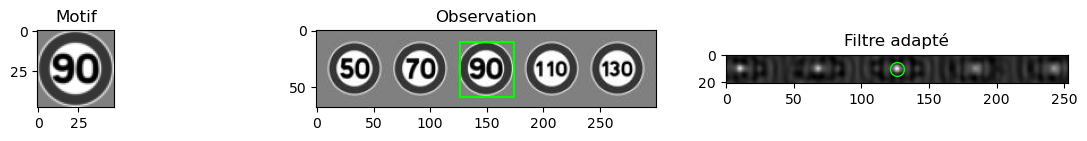

In [5]:
img = io.imread('../_static/panneaux.jpg')
sign = io.imread("../_static/P90.png")
res = match_template(img, sign)
display(img, sign, res, (15, 1))

### Un panneau, une taille, sur une image réelle

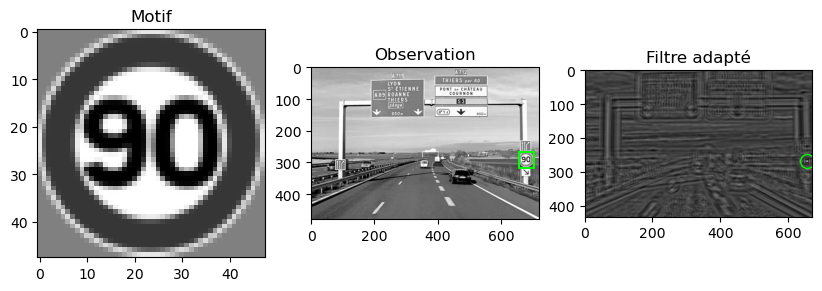

In [6]:
# Observation
img = io.imread('../_static/route1.jpg')
sign = io.imread("../_static/P90.png")
res = match_template(img, sign)
display(img, sign, res, (10, 3))

## Un panneau, plusieurs tailles, sur une image réelle

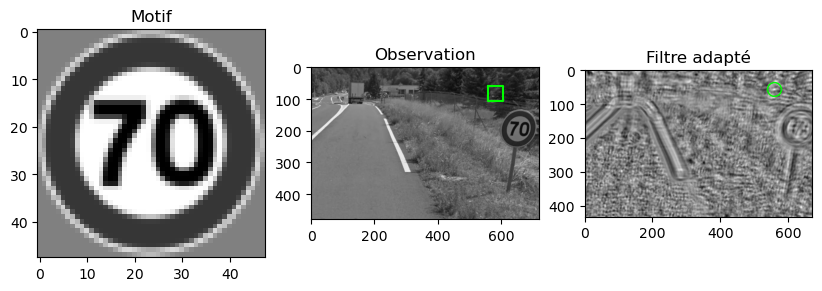

In [7]:
# Observation
img = io.imread('../_static/route6.jpg')
sign = io.imread("../_static/P70.png")
res = match_template(img, sign)
display(img, sign, res, (10, 3))

Corrélation la plus forte (0.721) pour une taille 118×118


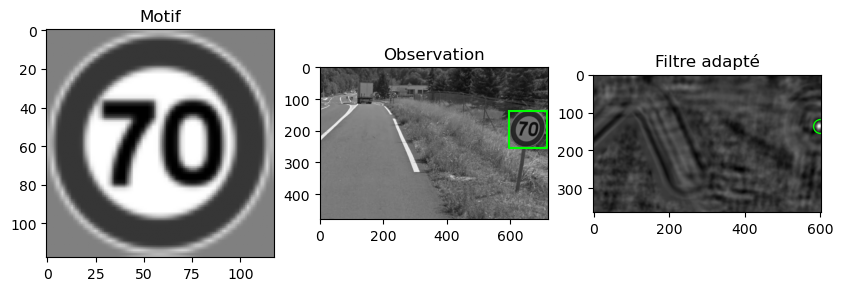

In [8]:
# Observation
img = io.imread('../_static/route6.jpg')
template = io.imread("../_static/P70.png")

# Plusieurs tailles
Sbest = 0
rbest = 0
for S in range(18,128,10):
    sign = resize(template, (S,S))
    res = match_template(img, sign)
    if np.max(res) > rbest:
        rbest = np.max(res)
        Sbest = S

print(f"Corrélation la plus forte ({rbest:.3f}) pour une taille {Sbest}×{Sbest}")

sign = resize(template, (Sbest,Sbest))
res = match_template(img, sign)
display(img, sign, res, (10, 3))

Temps de calcul : 282.713 ms
Panneau 50 : corrélation la plus forte (0.366) pour une taille 38×38


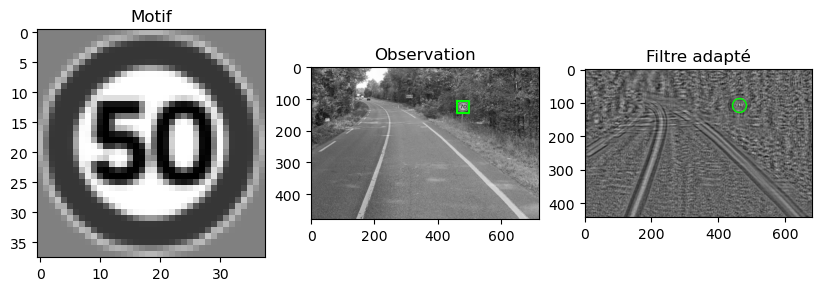

Temps de calcul : 273.639 ms
Panneau 70 : corrélation la plus forte (0.519) pour une taille 38×38


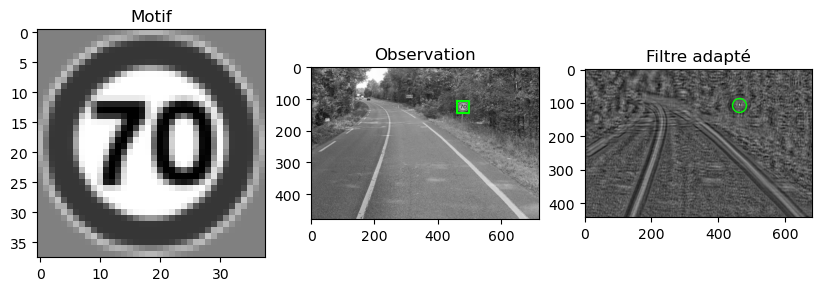

Temps de calcul : 263.942 ms
Panneau 90 : corrélation la plus forte (0.350) pour une taille 18×18


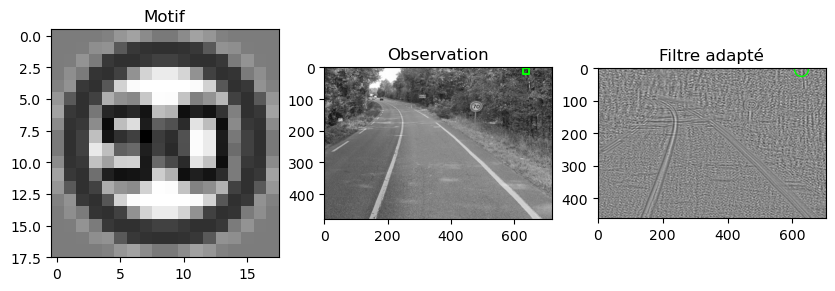

Temps de calcul : 282.969 ms
Panneau 110 : corrélation la plus forte (0.432) pour une taille 18×18


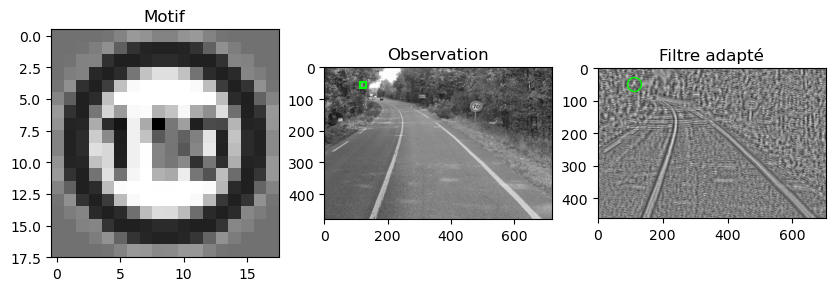

Temps de calcul : 259.771 ms
Panneau 130 : corrélation la plus forte (0.430) pour une taille 18×18


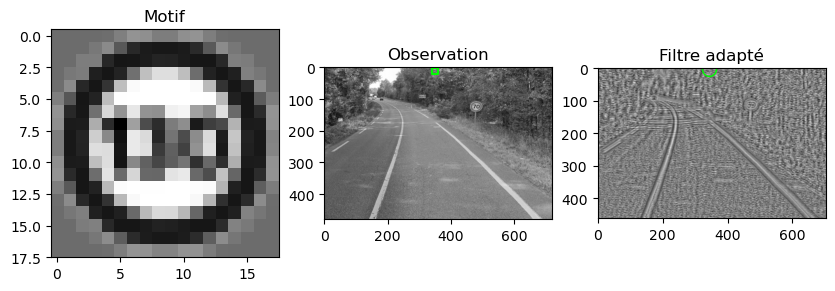

In [9]:
# Observation
img = io.imread('../_static/route2.jpg')

panels = [50, 70, 90, 110, 130]

for P in panels:

    # Panneau
    template = io.imread(f"../_static/P{P}.png")
    
    start_time = time.time()
    
    Sbest = 0
    rbest = 0
    
    for S in range(18,128,10):
    
        sign = resize(template, (S,S))
        res = match_template(img, sign)
        if np.max(res) > rbest:
            rbest = np.max(res)
            Sbest = S
            
    print(f"Temps de calcul : {(time.time()-start_time)*1e3:.3f} ms")
    print(f"Panneau {P} : corrélation la plus forte ({rbest:.3f}) pour une taille {Sbest}×{Sbest}")
    
    sign = resize(template, (Sbest,Sbest))
    res = match_template(img, sign)
    display(img, sign, res, (10, 3))

## Algorithme SIFT

Temps de calcul : 9.049 ms


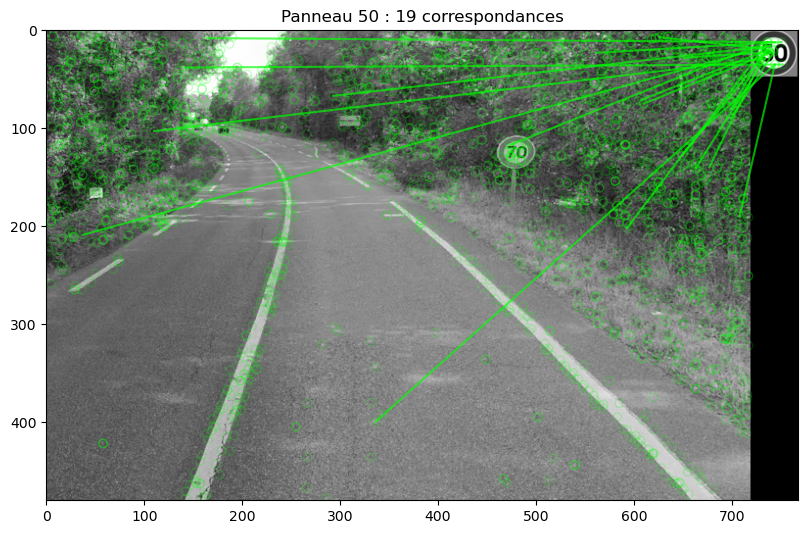

Temps de calcul : 9.072 ms


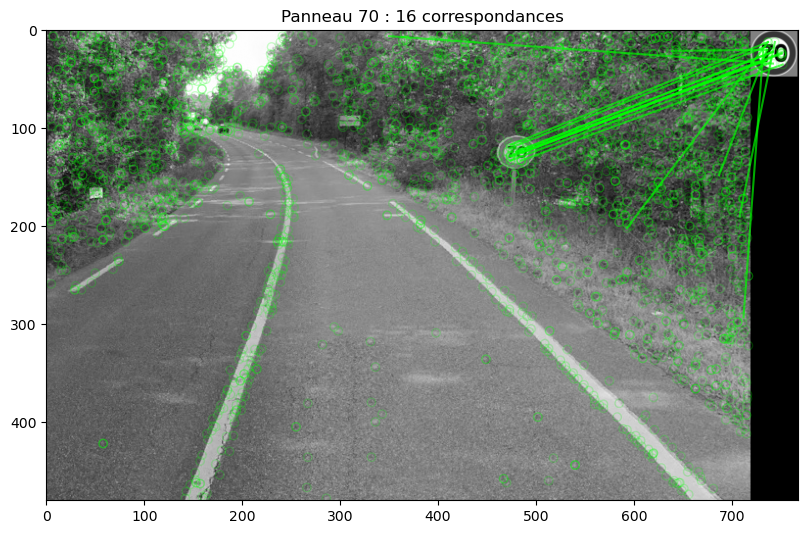

Temps de calcul : 11.911 ms


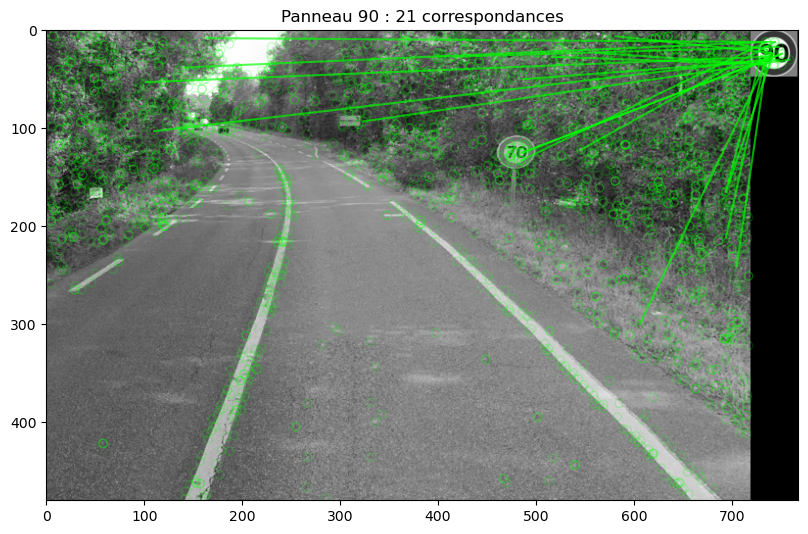

Temps de calcul : 10.790 ms


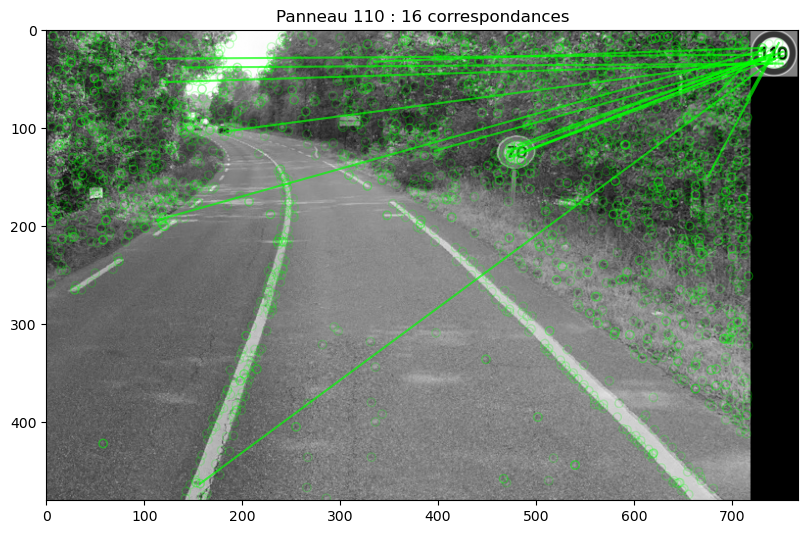

Temps de calcul : 10.863 ms


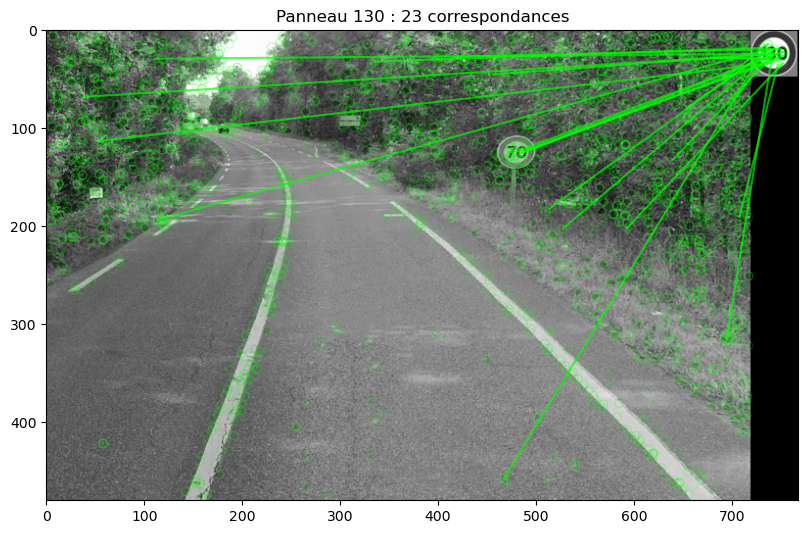

In [10]:
# Observation
img = io.imread('../_static/route2.jpg')

# Motifs
panels = [50, 70, 90, 110, 130]

# SIFT sur l'image
descriptor_extractor = SIFT()
descriptor_extractor.detect_and_extract(img)
keypoints0 = descriptor_extractor.keypoints
descriptors0 = descriptor_extractor.descriptors

for P in panels:

    # Motif
    sign = io.imread(f"../_static/P{P}.png")

    # Temps de calcul
    start_time = time.time()

    # SIFT sur le panneau
    descriptor_extractor.detect_and_extract(sign)
    keypoints1 = descriptor_extractor.keypoints
    descriptors1 = descriptor_extractor.descriptors

    # Matching
    matches = match_descriptors(descriptors0, descriptors1)#, max_ratio=.8)
    
    print(f"Temps de calcul : {(time.time()-start_time)*1e3:.3f} ms")

    # Affichage
    plt.figure(figsize=(10, 5))
    plot_matched_features(
        img,
        sign,
        keypoints0=keypoints0,
        keypoints1=keypoints1,
        matches=matches,
        matches_color='#0f0a',
        keypoints_color='#0f03',
        ax=plt.gca(),
    )
    plt.tight_layout()
    plt.xlim(0,img.shape[1]+sign.shape[1])
    plt.title(f"Panneau {P} : {matches.shape[0]} correspondances")
    plt.show()